This program will be dedicated to finding the Nusselt numbers as a function of Ra (and possibly also of Pr)

In [1]:
import sys
print(sys.executable)

/opt/anaconda3/envs/dedalus3/bin/python


In [2]:
import os
os.environ['OMP_NUM_THREADS'] = '1'      # must be set before numpy is imported
os.environ['NUMEXPR_MAX_THREADS'] = '1'

import sys
import numpy as np
import matplotlib.pyplot as plt
import dedalus.public as d3

from mpi4py import MPI
import time

import logging
logging.disable(logging.INFO)   # hide INFO messages (Dedalus's "Building subproblem matrices..." lines)

from scipy.optimize import brentq, minimize_scalar

%matplotlib inline
print(sys.executable)

/opt/anaconda3/envs/dedalus3/bin/python


In [3]:
import os, shutil, pathlib
import h5py

In [4]:
import pandas as pd

In [112]:
GAP_TOL = 2.0 # % : max allowed |Nu_vol - Nu_wall| / Nu_wall for a run to count as converged.

In [30]:
def run_filename(Ra, Pr, Nx, Nz):
    """Name of a run's output file, so the simulation and the analysis always agree."""
    tag = f"Ra{Ra:.2e}_Pr{Pr:g}_Nx{Nx}_Nz{Nz}".replace('+', '').replace('.', 'p')
    return f'xavg_{tag}.npz'

In [96]:
# CREDIT: adapted from the Dedalus examples repository (ivp_2d_rayleigh_benard)
def run_rayleigh_benard(Rayleigh, stop_sim_time, Prandtl=1, Nx=256, Nz=64, Lx=4, Lz=1,
                        outfile=None, overwrite=False, sample_dt=0.25, max_timestep=0.125,cfl_safety=0.5, cfl_cadence=10):
    """
    2D horizontally periodic Rayleigh-Benard convection, no-slip walls, fixed temperature.
    Free-fall units: kappa = (Ra Pr)^(-1/2), nu = (Ra/Pr)^(-1/2).
    Every sample_dt of simulation time, stores the x-averages of b, w*b and w (no snapshot files).
    Saves them with t, z and the run parameters to xavg_Ra..._Pr..._Nx..._Nz....npz.
    Skipped if that file exists unless overwrite=True.
    Returns (outfile, wall_time_in_seconds); wall_time is None if skipped.
    """
    if outfile is None:
        outfile = run_filename(Rayleigh, Prandtl, Nx, Nz)
    if os.path.exists(outfile) and not overwrite:
        print(f'{outfile} already exists: skipping (use overwrite=True to rerun)')
        return outfile, None

    dealias = 3/2
    timestepper = d3.RK222
    dtype = np.float64

    # Bases
    coords = d3.CartesianCoordinates('x', 'z')
    dist = d3.Distributor(coords, dtype=dtype)
    xbasis = d3.RealFourier(coords['x'], size=Nx, bounds=(0, Lx), dealias=dealias)
    zbasis = d3.ChebyshevT(coords['z'], size=Nz, bounds=(0, Lz), dealias=dealias)

    # Fields
    p = dist.Field(name='p', bases=(xbasis, zbasis))
    b = dist.Field(name='b', bases=(xbasis, zbasis))
    u = dist.VectorField(coords, name='u', bases=(xbasis, zbasis))
    tau_p = dist.Field(name='tau_p')
    tau_b1 = dist.Field(name='tau_b1', bases=xbasis)
    tau_b2 = dist.Field(name='tau_b2', bases=xbasis)
    tau_u1 = dist.VectorField(coords, name='tau_u1', bases=xbasis)
    tau_u2 = dist.VectorField(coords, name='tau_u2', bases=xbasis)

    # Substitutions
    kappa = (Rayleigh * Prandtl)**(-1/2)
    nu = (Rayleigh / Prandtl)**(-1/2)
    x, z = dist.local_grids(xbasis, zbasis)
    ex, ez = coords.unit_vector_fields(dist)
    lift_basis = zbasis.derivative_basis(1)
    lift = lambda A: d3.Lift(A, lift_basis, -1)
    grad_u = d3.grad(u) + ez*lift(tau_u1)
    grad_b = d3.grad(b) + ez*lift(tau_b1)

    # Problem
    problem = d3.IVP([p, b, u, tau_p, tau_b1, tau_b2, tau_u1, tau_u2], namespace=locals())
    problem.add_equation("trace(grad_u) + tau_p = 0")
    problem.add_equation("dt(b) - kappa*div(grad_b) + lift(tau_b2) = - u@grad(b)")
    problem.add_equation("dt(u) - nu*div(grad_u) + grad(p) - b*ez + lift(tau_u2) = - u@grad(u)")
    problem.add_equation("b(z=0) = Lz")
    problem.add_equation("u(z=0) = 0")
    problem.add_equation("b(z=Lz) = 0")
    problem.add_equation("u(z=Lz) = 0")
    problem.add_equation("integ(p) = 0")

    # Solver
    solver = problem.build_solver(timestepper)
    solver.stop_sim_time = stop_sim_time

    # Initial conditions: linear profile + small noise (seed fixed for reproducibility only)
    b.fill_random('g', seed=42, distribution='normal', scale=1e-3)
    b['g'] *= z * (Lz - z)
    b['g'] += Lz - z

    # CFL
    CFL = d3.CFL(solver, initial_dt=max_timestep, cadence=cfl_cadence, safety=cfl_safety, threshold=0.05,
                 max_change=1.5, min_change=0.5, max_dt=max_timestep)
    CFL.add_velocity(u)

    # Storage for the x-averaged profiles
    w = u @ ez
    t_s, b_s, wb_s, w_s = [], [], [], []
    next_sample = 0.0

    # Main loop
    t0 = time.time()
    while solver.proceed:
        timestep = CFL.compute_timestep()
        solver.step(timestep)
        if solver.sim_time >= next_sample:
            wb_f = (w * b).evaluate(); wb_f.change_scales(1)
            w_f = w.evaluate();        w_f.change_scales(1)
            b.change_scales(1)
            t_s.append(solver.sim_time)
            b_s.append(b['g'].mean(axis=0))       # axis 0 = x (serial run)
            wb_s.append(wb_f['g'].mean(axis=0))
            w_s.append(w_f['g'].mean(axis=0))
            #add blow up guard:
            if not np.all(np.isfinite(wb_s[-1])):
               print(f'  Ra = {Rayleigh:.0e}: solution blew up at t = {solver.sim_time:.2f}. Stopping, nothing saved.')
               return None, None
            next_sample += sample_dt
        if solver.iteration % 200 == 0:
            print(f'  Ra = {Rayleigh:.0e}:  t = {solver.sim_time:.1f} / {stop_sim_time},  dt = {timestep:.4f}')
    wall_time = time.time() - t0

    np.savez(outfile, t=np.array(t_s), z=z.ravel(),
             b_x=np.array(b_s), wb_x=np.array(wb_s), w_x=np.array(w_s),
             Ra=Rayleigh, Pr=Prandtl, Nx=Nx, Nz=Nz, Lx=Lx, Lz=Lz, wall_time=wall_time,
             max_timestep=max_timestep,cfl_safety=cfl_safety, cfl_cadence=cfl_cadence)
    print(f'Ra = {Rayleigh:.0e} finished in {wall_time:.0f} s -> {outfile}')
    return outfile, wall_time

In [ ]:
#I will first run the RB simulation for Ra=2e6. 
#In last notebook, I ran this for 50 seconds, which was enough to settle, so I'll reuse that time.
#I also used the default resolution in both x and z (these haven't needed to be increased yet)

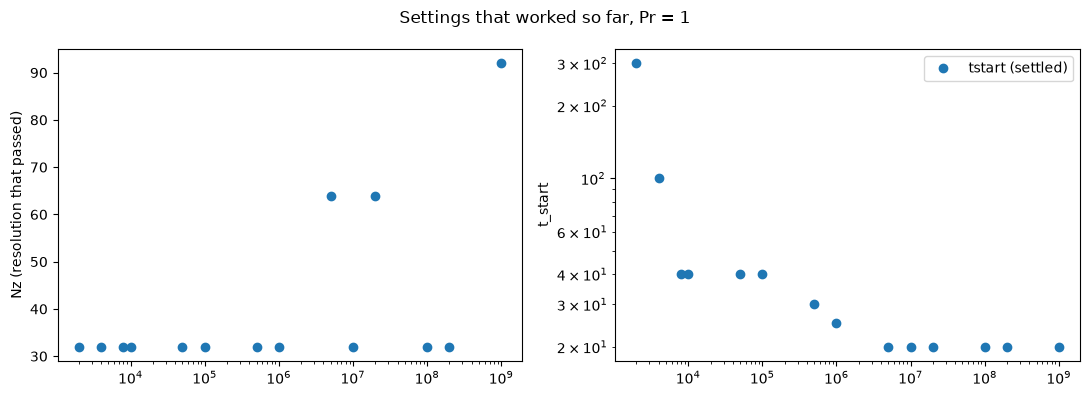

In [326]:
#The below code goes through the results csv and plots 2 subplots: Nz used vs Ra, and t_start vs Ra
#t_start is when the simulation settled, ie convection had fully set in
#It also plots a vertical line where the new Ra value to run is
#This lets me estimate what Nz and stop time to use
#the stop time must be greater than t_start and should allow enough data points after settling.
#I'll probably use stop_time = t_start + 50. 
#The first run, for 2e6, had t_start = 20 and t_stop =50, giving 30 settled time units, and this worked out fine.

log = pd.read_csv('nu_results copy.csv')
g = (log[log.Pr == Pr].sort_values('Nz')
        .drop_duplicates('Ra', keep='last').sort_values('Ra'))     # best resolution per Ra

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].semilogx(g.Ra, g.Nz, 'o')
ax[0].set_ylabel('Nz (resolution that passed)')


ax[1].plot(g.Ra, g.tstart, 'o', label='tstart (settled)')
ax[1].set_xscale('log'), ax[1].set_yscale('log')
ax[1].set_ylabel('t_start')
ax[1].legend()


plt.suptitle(f'Settings that worked so far, Pr = {Pr:g}')
plt.tight_layout(); plt.show()

In [313]:
#Now run the new simulation with appropriate params
Ra, Pr = 2e6, 1
Nz = 32
Nx = 4*Nz
t_start = 20 #estimate when convection will start
sim_length = 50 #adjust to be higher for Ra_s near Ra_c, bc convection takes longer to get going
stop_time = t_start+sim_length #so sim will stop 50 seconds after the convection has started 
print(f"Running new simulation with Ra = {Ra} and Pr = {Pr}")

##Use line below if running for a Ra roughly < 1e9
run_rayleigh_benard(Ra, stop_time, Prandtl=Pr, Nx=Nx, Nz=Nz,overwrite=False)

##Uncomment below line if Running for Ra>1e9 - needed in increase the temp res to avoid blow ups (overflows)
#run_rayleigh_benard(Ra, stop_time, Prandtl=1, Nx=Nx, Nz=Nz, max_timestep=0.03, cfl_safety=0.3, cfl_cadence=2, overwrite=False) 

Running new simulation with Ra = 2000000.0 and Pr = 1
xavg_Ra2p00e06_Pr1_Nx128_Nz32.npz already exists: skipping (use overwrite=True to rerun)


('xavg_Ra2p00e06_Pr1_Nx128_Nz32.npz', None)

In [321]:
# Load a saved run (xavg_*.npz) and compute Nu_vol(t), the Nusselt number from the volume-averaged
# heat flux: Nu_vol = 1 + <wb>_V / kappa = 1 + sqrt(Ra*Pr) * <wb>_V, at every saved time.
# <wb>_V is the x-average of wb (already stored) integrated over z (trapezoid rule) divided by Lz.
# The file is chosen from the Ra, Pr, Nx, Nz set in the settings cell.
# Result: Nu_vol_t (one value per saved time). Also loads t, z, b_x, wb_x, w_x for the cells below.
fname = run_filename(Ra, Pr, Nx, Nz)
d = np.load(fname)
assert float(d['Ra']) == Ra and float(d['Pr']) == Pr      # sanity check: file matches the settings
t, z = d['t'], d['z']
b_x, wb_x, w_x = d['b_x'], d['wb_x'], d['w_x']
Lz = float(d['Lz'])
kappa = (Ra * Pr)**(-1/2)
# volume average of wb at each time: trapezoid in z, with wb = 0 at the two walls
z_ext = np.concatenate(([0], z, [Lz]))
wb_ext = np.pad(wb_x, ((0, 0), (1, 1)))
wb_V = np.trapezoid(wb_ext, z_ext, axis=1) / Lz
Nu_vol_t = 1 + wb_V / kappa

In [33]:
''' Edited out because no longer need. 
I have estblished that kappa conversion factor IS needed, which is implemented on pen line of above cell
# Test whether to use the kappa factor or not. From previous notebook 
#using just wall gradient, expect Nu~9 for Ra=2e6
#Nu_vol_t_with_kappa = 1 + wb_V / kappa
#Nu_vol_t_without_kappa = 1 + wb_V
#print('Nu with kappa factor: ', Nu_vol_t_with_kappa.mean())
#print('Nu without kappa factor: ', Nu_vol_t_without_kappa.mean())
''' 


Nu with kappa factor:  9.068621621808123
Nu without kappa factor:  1.0057053770636089


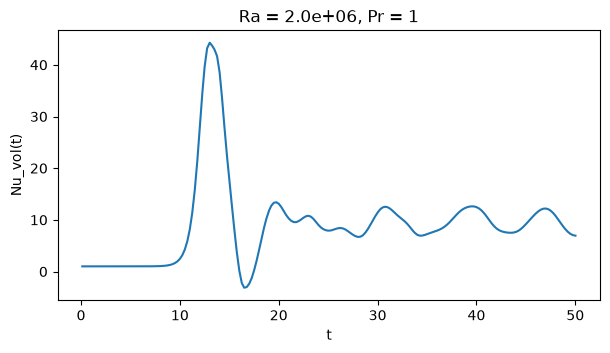

In [322]:
#plot Nu over time as a settling check (replacing the old settling check method):
plt.figure(figsize=(7, 3.5))
plt.plot(t, Nu_vol_t)
plt.xlabel('t'); plt.ylabel('Nu_vol(t)'); plt.title(f'Ra = {Ra:.1e}, Pr = {Pr:g}')
plt.show()

In [323]:
tstart = 25        # <- set from the settling plot no
dNz = 32             # how much Nz increases on a failed run

m = t >= tstart
# Nu from the volume average of wb
Nu_vol = Nu_vol_t[m].mean()
blocks = np.array_split(Nu_vol_t[m], 4)
#use block scatter method to find error in Nu
Nu_err = np.std([blk.mean() for blk in blocks], ddof=1) / np.sqrt(len(blocks))

# Nu from the wall gradient of the time-mean profile (parabola through wall + two nearest points)
bm = b_x[m].mean(axis=0)
a2, a1, a0 = np.polyfit([0, z[0], z[1]], [Lz, bm[0], bm[1]], 2);   Nu_bot = -a1
s = Lz - z
c2, c1, c0 = np.polyfit([0, s[-1], s[-2]], [0, bm[-1], bm[-2]], 2); Nu_top = c1
Nu_wall = 0.5 * (Nu_bot + Nu_top)

gap = 100 * (Nu_vol - Nu_wall) / Nu_wall
print(f'Nu_vol  = {Nu_vol:.3f} ± {Nu_err:.3f}')
print(f'Nu_wall = {Nu_wall:.3f}   (bottom {Nu_bot:.3f}, top {Nu_top:.3f})')
print(f'gap     = {gap:.2f} %   (tolerance {GAP_TOL} %)')

if abs(gap) <= GAP_TOL:
    print('PASS: methods agree within tolerance.')
else:
    Nz_new = Nz + dNz
    print(f'FAIL: methods disagree by more than the tolerance. Refine the resolution and rerun with a Nz=:{Nz_new}')

Nu_vol  = 9.405 ± 0.354
Nu_wall = 9.491   (bottom 9.680, top 9.302)
gap     = -0.91 %   (tolerance 2.0 %)
PASS: methods agree within tolerance.


In [299]:
#This cell writes results to CSV file but only if wall and volume method agree within 2% 

#This func is necessary bc the initial npz files didnt save max_dit, safety or cadence vals.
def saved(key, default):
    """Read a setting from the .npz, or use a default for files saved before it was recorded."""
    return float(d[key]) if key in d.files else default

if abs(gap) <= GAP_TOL:
    logfile = 'nu_results.csv'
    Nx, Nz = int(d['Nx']), int(d['Nz'])
    row = dict(Ra=Ra, Pr=Pr, Nx=Nx, Nz=Nz, tstart=tstart, t_end=t[-1],
               Nu_vol=Nu_vol, Nu_err=Nu_err, Nu_wall=Nu_wall, gap_pct=gap,
               wall_min=float(d['wall_time']) / 60,
               max_dt=saved('max_timestep', 0.125),
               cfl_safety=saved('cfl_safety', 0.5),
               cfl_cadence=int(saved('cfl_cadence', 10)))

    new = pd.DataFrame([row])
    if os.path.exists(logfile):
        old = pd.read_csv(logfile)
        same = (old.Ra == Ra) & (old.Pr == Pr) & (old.Nx == Nx) & (old.Nz == Nz)
        new = pd.concat([old[~same], new])          # rerunning the same setup replaces its row
    new.sort_values(['Pr', 'Ra']).to_csv(logfile, index=False)
    #print(new.sort_values(['Pr', 'Ra']).to_string(index=False))
    print('Finished')
else:
    print('Not logged: gap above tolerance. Rerun at higher resolution first.')

Finished


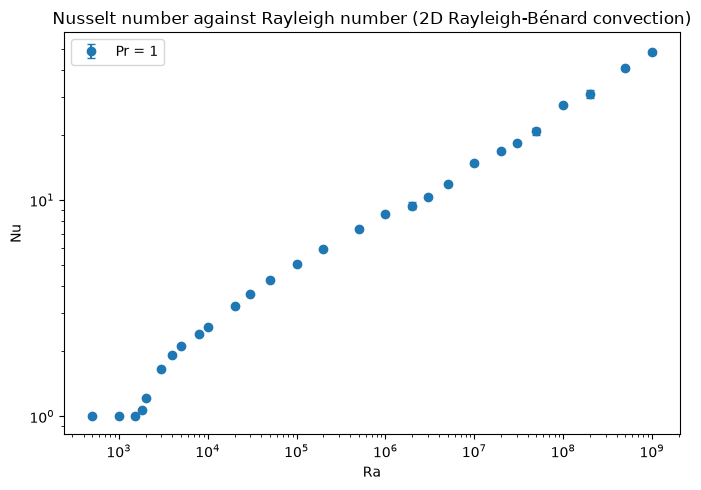

In [324]:
df = pd.read_csv('nu_results.csv')
df = df.sort_values('Nz').drop_duplicates(['Ra', 'Pr'], keep='last')   # best resolution per (Ra, Pr)

plt.figure(figsize=(7, 5))
for Pr_val, g in df.groupby('Pr'):
    g = g.sort_values('Ra')
    plt.errorbar(g.Ra, g.Nu_vol, yerr=g.Nu_err, fmt='o', capsize=3, label=f'Pr = {Pr_val:g}')
plt.xscale('log'); plt.yscale('log')
plt.xlabel('Ra'); plt.ylabel('Nu')
plt.title('Nusselt number against Rayleigh number (2D Rayleigh-Bénard convection)')
plt.legend()
plt.tight_layout(); plt.show()